In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [24]:
customer = pd.read_csv("C:/Users/pooja/OneDrive/Desktop/python case study/Case Study 2 - Credit Card Case Study/Customer Acqusition.csv")
    

repayment = pd.read_csv("C:/Users/pooja/OneDrive/Desktop/python case study/Case Study 2 - Credit Card Case Study/Repayment.csv")
    

spend = pd.read_csv("C:/Users/pooja/OneDrive/Desktop/python case study/Case Study 2 - Credit Card Case Study/spend.csv")


In [25]:
customer.head()

,No,Customer,Age,City,Product,Limit,Company,Segment
0,1,A1,76,BANGALORE,Gold,500000.0,C1,Self Employed
1,2,A2,71,CALCUTTA,Silver,100000.0,C2,Salaried_MNC
2,3,A3,34,COCHIN,Platimum,10000.0,C3,Salaried_Pvt
3,4,A4,47,BOMBAY,Platimum,10001.0,C4,Govt
4,5,A5,56,BANGALORE,Platimum,10002.0,C5,Normal Salary


In [26]:
repayment.head()

,SL No:,Customer,Month,Amount,Unnamed: 4
0,NaN,A1,12-Jan-04,495414.75,NaN
1,2.0,A1,3-Jan-04,245899.02,NaN
2,3.0,A1,15-Jan-04,259490.06,NaN
3,4.0,A1,25-Jan-04,437555.12,NaN
4,5.0,A1,17-Jan-05,165972.88,NaN


In [27]:
spend.head()

,Sl No:,Customer,Month,Type,Amount
0,1,A1,12-Jan-04,JEWELLERY,485470.80
1,2,A1,3-Jan-04,PETRO,410556.13
2,3,A1,15-Jan-04,CLOTHES,23740.46
3,4,A1,25-Jan-04,FOOD,484342.47
4,5,A1,17-Jan-05,CAMERA,369694.07


In [28]:
print("Customer Shape:", customer.shape)
print("Spend Shape:", spend.shape)
print("Repayment Shape:", repayment.shape)

Customer Shape: (100, 8)
Spend Shape: (1500, 5)
Repayment Shape: (1523, 5)


In [29]:
print(customer.columns)
print(repayment.columns)
print(spend.columns)


Index(['No', 'Customer', 'Age', 'City', 'Product', 'Limit', 'Company',
       'Segment'],
      dtype='object')
Index(['SL No:', 'Customer', 'Month', 'Amount', 'Unnamed: 4'], dtype='object')
Index(['Sl No:', 'Customer', 'Month', 'Type', 'Amount'], dtype='object')


In [30]:
print(customer.info())
print(repayment.info())
print(spend.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   No        100 non-null    int64  
 1   Customer  100 non-null    object 
 2   Age       100 non-null    int64  
 3   City      100 non-null    object 
 4   Product   100 non-null    object 
 5   Limit     100 non-null    float64
 6   Company   100 non-null    object 
 7   Segment   100 non-null    object 
dtypes: float64(1), int64(2), object(5)
memory usage: 6.4+ KB
None
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1523 entries, 0 to 1522
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   SL No:      1499 non-null   float64
 1   Customer    1500 non-null   object 
 2   Month       1500 non-null   object 
 3   Amount      1500 non-null   float64
 4   Unnamed: 4  0 non-null      float64
dtypes: float64(3), object(2)
memory usage: 59.

In [31]:
print("Customer Missing Values")
print(customer.isnull().sum())
print("Repayment Missing Values")
print(repayment.isnull().sum())
print("Spend Missing Values")
print(spend.isnull().sum())

Customer Missing Values
No          0
Customer    0
Age         0
City        0
Product     0
Limit       0
Company     0
Segment     0
dtype: int64
Repayment Missing Values
SL No:          24
Customer        23
Month           23
Amount          23
Unnamed: 4    1523
dtype: int64
Spend Missing Values
Sl No:      0
Customer    0
Month       0
Type        0
Amount      0
dtype: int64


In [32]:
print("Customer Duplicates:", customer.duplicated().sum())
print("Repayment Duplicates:", repayment.duplicated().sum())
print("Spend Duplicates:", spend.duplicated().sum())

Customer Duplicates: 0
Repayment Duplicates: 22
Spend Duplicates: 0


In [33]:
customer.columns = customer.columns.str.strip()
repayment.columns = repayment.columns.str.strip()
spend.columns = spend.columns.str.strip()
print(customer.columns)
print(spend.columns)
print(repayment.columns)

Index(['No', 'Customer', 'Age', 'City', 'Product', 'Limit', 'Company',
       'Segment'],
      dtype='object')
Index(['Sl No:', 'Customer', 'Month', 'Type', 'Amount'], dtype='object')
Index(['SL No:', 'Customer', 'Month', 'Amount', 'Unnamed: 4'], dtype='object')


In [34]:
print(customer.isnull().sum())
print(repayment.isnull().sum())
print(spend.isnull().sum())

No          0
Customer    0
Age         0
City        0
Product     0
Limit       0
Company     0
Segment     0
dtype: int64
SL No:          24
Customer        23
Month           23
Amount          23
Unnamed: 4    1523
dtype: int64
Sl No:      0
Customer    0
Month       0
Type        0
Amount      0
dtype: int64


In [35]:
spend.columns.tolist()

['Sl No:', 'Customer', 'Month', 'Type', 'Amount']

In [36]:
# Remove rows missing essential customer information

customer = customer.dropna(
    subset=['Customer', 'Age', 'City', 'Product', 'Limit']
).copy()

# Remove rows missing essential transaction information

repayment = repayment.dropna(
    subset=['Customer', 'Month', 'Amount']
).copy()

spend= spend.dropna(
    subset=['Customer', 'Month','Type', 'Amount']
).copy()

In [37]:
# Convert Month columns to datetime
spend['Month'] = pd.to_datetime(
    spend['Month'],
    errors='coerce'
)

repayment['Month'] = pd.to_datetime(
    repayment['Month'],
    errors='coerce'
)

# Remove rows with invalid dates

spend = spend.dropna(subset=['Month']).copy()
repayment = repayment.dropna(subset=['Month']).copy()

In [38]:
repayment.info()
spend.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1500 entries, 0 to 1499
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   SL No:      1499 non-null   float64       
 1   Customer    1500 non-null   object        
 2   Month       1500 non-null   datetime64[ns]
 3   Amount      1500 non-null   float64       
 4   Unnamed: 4  0 non-null      float64       
dtypes: datetime64[ns](1), float64(3), object(1)
memory usage: 70.3+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Sl No:    1500 non-null   int64         
 1   Customer  1500 non-null   object        
 2   Month     1500 non-null   datetime64[ns]
 3   Type      1500 non-null   object        
 4   Amount    1500 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(2)
memo

In [39]:
# Extract year
repayment['Year'] = repayment['Month'].dt.year
spend['Year'] = spend['Month'].dt.year

# Extract month number
repayment['Month_Number'] = repayment['Month'].dt.month
spend['Month_Number'] = spend['Month'].dt.month

# Extract year-month period
repayment['Year_Month'] = repayment['Month'].dt.to_period('M')
spend['Year_Month'] = spend['Month'].dt.to_period('M')

spend.columns.tolist()

['Sl No:',
 'Customer',
 'Month',
 'Type',
 'Amount',
 'Year',
 'Month_Number',
 'Year_Month']

In [40]:
# Calculate the mean age

mean_age = customer['Age'].mean()

print("Mean Age:", mean_age)

# Replace ages below 18 with the mean age

customer.loc[
    customer['Age'] < 18,
    'Age'
] = mean_age

# Verify

print(customer[customer['Age'] < 18])

Mean Age: 46.49
Empty DataFrame
Columns: [No, Customer, Age, City, Product, Limit, Company, Segment]
Index: []


In [42]:
# Select customer columns required for analysis

customer_info = customer[
    [
        'Customer',
        'Age',
        'City',
        'Product',
        'Limit',
        'Company',
        'Segment'
    ]
].copy()

# Merge customer information with spending transactions

spend = pd.merge(
    spend,
    customer_info,
    on='Customer',
    how='left',
    validate='many_to_one'
)

# Display the merged data
display(spend.head())

,Sl No:,Customer,Month,Type,Amount,Year,Month_Number,Year_Month,Age,City,Product,Limit,Company,Segment
0,1,A1,2004-01-12,JEWELLERY,485470.80,2004,1,2004-01,76.0,BANGALORE,Gold,500000.0,C1,Self Employed
1,2,A1,2004-01-03,PETRO,410556.13,2004,1,2004-01,76.0,BANGALORE,Gold,500000.0,C1,Self Employed
2,3,A1,2004-01-15,CLOTHES,23740.46,2004,1,2004-01,76.0,BANGALORE,Gold,500000.0,C1,Self Employed
3,4,A1,2004-01-25,FOOD,484342.47,2004,1,2004-01,76.0,BANGALORE,Gold,500000.0,C1,Self Employed
4,5,A1,2005-01-17,CAMERA,369694.07,2005,1,2005-01,76.0,BANGALORE,Gold,500000.0,C1,Self Employed


In [43]:
# Identify transactions exceeding the credit limit

spend_over_limit = spend[
    spend['Amount'] > spend['Limit']
]

print("Transactions exceeding limit:", len(spend_over_limit))

Transactions exceeding limit: 607


In [44]:
# Replace excessive spending amounts

spend.loc[
    spend['Amount'] > spend['Limit'],
    'Amount'
] = (
    spend.loc[
        spend['Amount'] > spend['Limit'],
        'Limit'
    ] * 0.50
)

In [45]:
print(
    "Remaining transactions above limit:",
    (spend['Amount'] > spend['Limit']).sum()
)

Remaining transactions above limit: 0


In [46]:
# Merge customer information with repayment transactions

repayment = pd.merge(
    repayment,
    customer_info,
    on='Customer',
    how='left',
    validate='many_to_one'
)

display(repayment.head())

,SL No:,Customer,Month,Amount,Unnamed: 4,Year,Month_Number,Year_Month,Age,City,Product,Limit,Company,Segment
0,NaN,A1,2004-01-12,495414.75,NaN,2004,1,2004-01,76.0,BANGALORE,Gold,500000.0,C1,Self Employed
1,2.0,A1,2004-01-03,245899.02,NaN,2004,1,2004-01,76.0,BANGALORE,Gold,500000.0,C1,Self Employed
2,3.0,A1,2004-01-15,259490.06,NaN,2004,1,2004-01,76.0,BANGALORE,Gold,500000.0,C1,Self Employed
3,4.0,A1,2004-01-25,437555.12,NaN,2004,1,2004-01,76.0,BANGALORE,Gold,500000.0,C1,Self Employed
4,5.0,A1,2005-01-17,165972.88,NaN,2005,1,2005-01,76.0,BANGALORE,Gold,500000.0,C1,Self Employed


In [47]:
# Identify repayments exceeding the limit

repayment_over_limit = repayment[
    repayment['Amount'] > repayment['Limit']
]

print("Repayments exceeding limit:", len(repayment_over_limit))

Repayments exceeding limit: 600


In [49]:
print(
    "Remaining repayments above limit:",
    (repayment['Amount'] > repayment['Limit']).sum()
)

Remaining repayments above limit: 600


In [50]:
# Count distinct customers

distinct_customers = customer['Customer'].nunique()

print("Number of Distinct Customers:", distinct_customers)

Number of Distinct Customers: 100


In [52]:
# Count distinct spending categories

distinct_categories = spend['Type'].nunique()

print("Number of Distinct Categories:", distinct_categories)

Number of Distinct Categories: 15


In [53]:
print(spend['Type'].unique())

['JEWELLERY' 'PETRO' 'CLOTHES' 'FOOD' 'CAMERA' 'SANDALS' 'CAR' 'BIKE'
 'AUTO' 'SHOPPING' 'AIR TICKET' 'BUS TICKET' 'TRAIN TICKET' 'RENTAL'
 'MOVIE TICKET']


In [54]:
category_count = spend['Type'].value_counts()

print(category_count)

Type
PETRO           200
FOOD            160
CAMERA          160
AIR TICKET      147
TRAIN TICKET    132
SHOPPING        113
BUS TICKET       99
JEWELLERY        95
CLOTHES          95
RENTAL           76
MOVIE TICKET     76
BIKE             49
AUTO             40
CAR              30
SANDALS          28
Name: count, dtype: int64


In [55]:
monthly_spend = spend.groupby(
    'Year_Month'
)['Amount'].sum().reset_index()

monthly_spend.columns = [
    'Year_Month',
    'Total_Spend'
]

display(monthly_spend.head())

,Year_Month,Total_Spend
0,2004-01,44279811.96
1,2004-02,3835951.84
2,2004-03,1871913.27
3,2004-04,3489415.34
4,2004-05,2146577.36


In [56]:
# Average total spending per calendar month

average_monthly_spend = monthly_spend['Total_Spend'].mean()

print(
    "Average Monthly Spend:",
    round(average_monthly_spend, 2)
)

Average Monthly Spend: 7326036.17


In [57]:
# Calculate total repayment for each calendar month

monthly_repayment = repayment.groupby(
    'Year_Month'
)['Amount'].sum().reset_index()

monthly_repayment.columns = [
    'Year_Month',
    'Total_Repayment'
]

display(monthly_repayment.head())

,Year_Month,Total_Repayment
0,2004-01,68177101.94
1,2004-02,6930971.03
2,2004-03,3788779.21
3,2004-04,7774250.37
4,2004-05,5654068.02


In [58]:
average_monthly_repayment = (
    monthly_repayment['Total_Repayment'].mean()
)

print(
    "Average Monthly Repayment:",
    round(average_monthly_repayment, 2)
)

Average Monthly Repayment: 12394502.72


In [59]:
monthly_summary = pd.merge(
    monthly_spend,
    monthly_repayment,
    on='Year_Month',
    how='outer'
)

# Replace missing monthly totals with zero

monthly_summary[
    ['Total_Spend', 'Total_Repayment']
] = monthly_summary[
    ['Total_Spend', 'Total_Repayment']
].fillna(0)

display(monthly_summary.head())

,Year_Month,Total_Spend,Total_Repayment
0,2004-01,44279811.96,68177101.94
1,2004-02,3835951.84,6930971.03
2,2004-03,1871913.27,3788779.21
3,2004-04,3489415.34,7774250.37
4,2004-05,2146577.36,5654068.02


In [60]:
# Calculate monthly profit

monthly_summary['Monthly_Profit'] = (
    monthly_summary['Total_Repayment']
    - monthly_summary['Total_Spend']
)

In [61]:
# Monthly interest rate

interest_rate = 0.029

# Calculate interest only on positive monthly profit

monthly_summary['Interest_Earned'] = (
    monthly_summary['Monthly_Profit']
    .clip(lower=0)
    * interest_rate
)
display(monthly_summary)

,Year_Month,Total_Spend,Total_Repayment,Monthly_Profit,Interest_Earned
0,2004-01,44279811.96,68177101.94,23897289.98,693021.40942
1,2004-02,3835951.84,6930971.03,3095019.19,89755.55651
2,2004-03,1871913.27,3788779.21,1916865.94,55589.11226
3,2004-04,3489415.34,7774250.37,4284835.03,124260.21587
4,2004-05,2146577.36,5654068.02,3507490.66,101717.22914
5,2004-09,2402109.69,2951805.58,549695.89,15941.18081
6,2004-11,1114989.10,3143883.57,2028894.47,58837.93963
7,2005-01,5383606.78,6494798.65,1111191.87,32224.56423
8,2005-02,25928183.21,38690340.95,12762157.74,370102.57446
9,2005-04,4100065.73,6380658.94,2280593.21,66137.20309


In [62]:
total_interest = monthly_summary['Interest_Earned'].sum()

print(
    "Total Interest Earned by Bank:",
    round(total_interest, 2)
)

Total Interest Earned by Bank: 4431248.77


In [63]:
average_monthly_interest = (
    monthly_summary['Interest_Earned'].mean()
)

print(
    "Average Monthly Interest:",
    round(average_monthly_interest, 2)
)


Average Monthly Interest: 147708.29


In [64]:
# Calculate total spend by category

product_spend = spend.groupby(
    'Type'
)['Amount'].sum().sort_values(
    ascending=False
)

# Select top five categories

top_5_products = product_spend.head(5)

print("Top 5 Spending Categories")
display(top_5_products)

Top 5 Spending Categories


Type
PETRO           28597384.98
CAMERA          27690738.44
FOOD            20519243.60
AIR TICKET      20155847.12
TRAIN TICKET    19995825.72
Name: Amount, dtype: float64

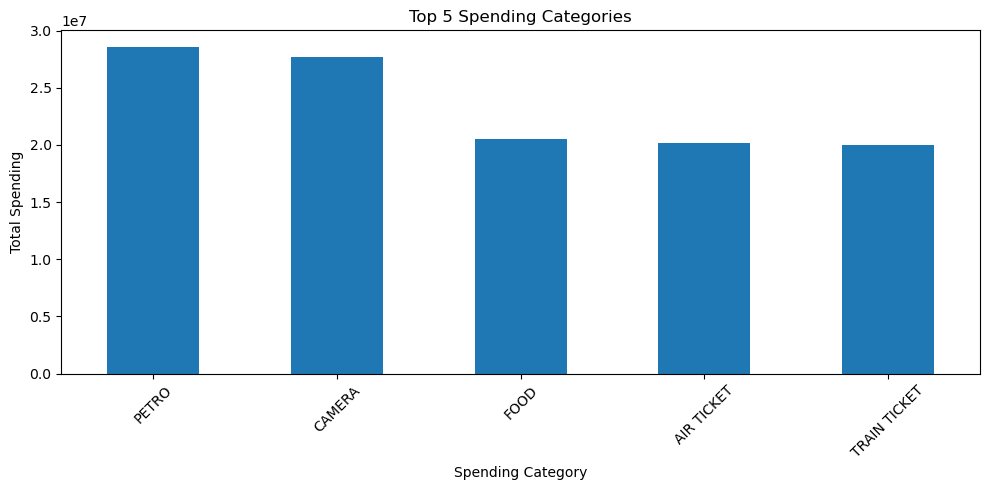

In [65]:
plt.figure(figsize=(10, 5))

top_5_products.plot(kind='bar')

plt.title('Top 5 Spending Categories')
plt.xlabel('Spending Category')
plt.ylabel('Total Spending')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [66]:
# Calculate city-wise spending

city_spend = spend.groupby(
    'City'
)['Amount'].sum().sort_values(
    ascending=False
)

print("City-wise Total Spending")
display(city_spend)

City-wise Total Spending


City
COCHIN        45963513.50
CALCUTTA      41108132.30
BANGALORE     40461647.02
BOMBAY        28603127.38
CHENNAI       22128635.65
TRIVANDRUM    15337155.87
PATNA         15260586.97
DELHI         10918286.54
Name: Amount, dtype: float64

In [67]:
maximum_spend_city = city_spend.idxmax()

maximum_spend_amount = city_spend.max()

print("City with Maximum Spending:", maximum_spend_city)

print(
    "Maximum Total Spending:",
    round(maximum_spend_amount, 2)
)

City with Maximum Spending: COCHIN
Maximum Total Spending: 45963513.5


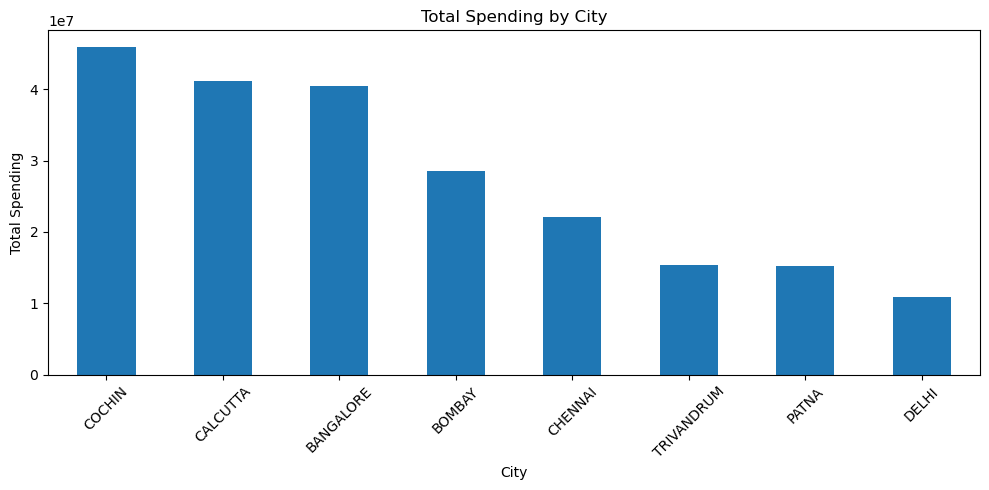

In [68]:
plt.figure(figsize=(10, 5))

city_spend.plot(kind='bar')

plt.title('Total Spending by City')
plt.xlabel('City')
plt.ylabel('Total Spending')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [69]:
# Define age groups

bins = [18, 25, 35, 45, 60, np.inf]

labels = [
    '18-25',
    '26-35',
    '36-45',
    '46-60',
    'Above 60'
]

# Create age group column

customer['Age_Group'] = pd.cut(
    customer['Age'],
    bins=bins,
    labels=labels,
    include_lowest=True
)

display(customer[['Customer', 'Age', 'Age_Group']].head())

,Customer,Age,Age_Group
0,A1,76.0,Above 60
1,A2,71.0,Above 60
2,A3,34.0,26-35
3,A4,47.0,46-60
4,A5,56.0,46-60


In [70]:
# Merge age group with spending data

spend = spend.drop(
    columns=['Age_Group'],
    errors='ignore'
)

spend = spend.merge(
    customer[['Customer', 'Age_Group']],
    on='Customer',
    how='left',
    validate='many_to_one'
)

In [71]:
# Calculate total spending by age group

age_group_spend = spend.groupby(
    'Age_Group',
    observed=False
)['Amount'].sum().sort_values(
    ascending=False
)

display(age_group_spend)

Age_Group
46-60       68690512.18
36-45       46312437.21
Above 60    43010625.38
26-35       37337313.16
18-25       24430197.30
Name: Amount, dtype: float64

In [72]:
top_age_group = age_group_spend.idxmax()

print("Highest Spending Age Group:", top_age_group)

Highest Spending Age Group: 46-60


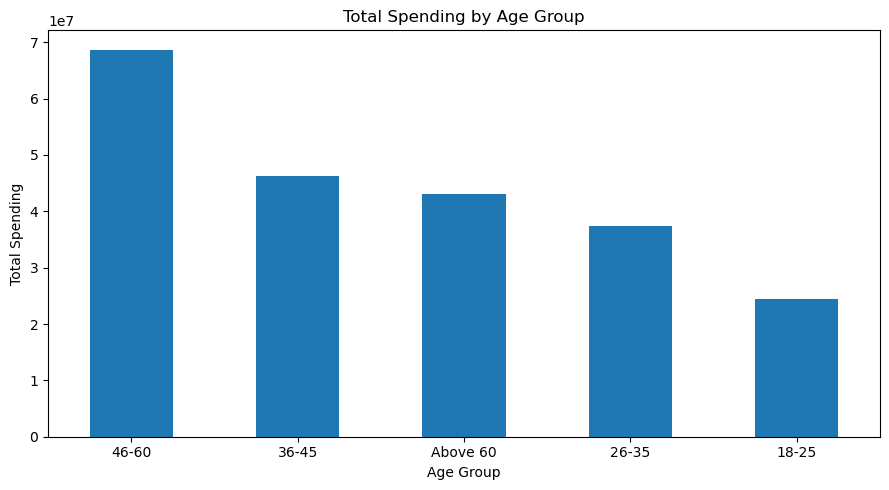

In [73]:
plt.figure(figsize=(9, 5))

age_group_spend.plot(kind='bar')

plt.title('Total Spending by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Total Spending')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [74]:
# Calculate total repayment for each customer

customer_repayment = repayment.groupby(
    'Customer'
)['Amount'].sum().sort_values(
    ascending=False
)

# Select top 10 customers

top_10_customers = customer_repayment.head(10)

print("Top 10 Customers by Repayment")
display(top_10_customers)

Top 10 Customers by Repayment


Customer
A61    10539142.91
A60     9876290.74
A13     9572000.66
A22     9372561.68
A21     9056336.15
A43     8489871.46
A45     8448334.87
A12     8334760.16
A48     8292416.75
A14     7943268.63
Name: Amount, dtype: float64

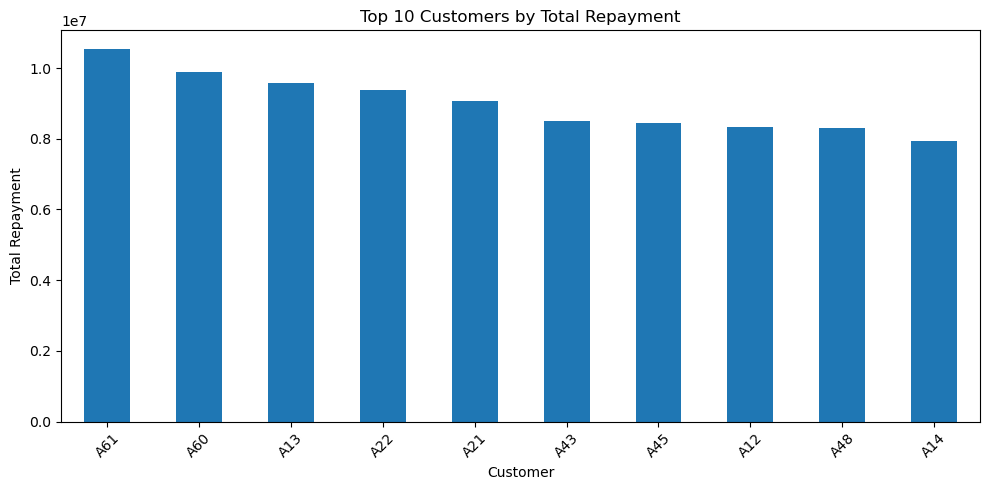

In [75]:
plt.figure(figsize=(10, 5))

top_10_customers.plot(kind='bar')

plt.title('Top 10 Customers by Total Repayment')
plt.xlabel('Customer')
plt.ylabel('Total Repayment')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [76]:
# Calculate city-wise spending by category and year

city_product_year = spend.groupby(
    ['City', 'Type', 'Year']
)['Amount'].sum().reset_index()

city_product_year = city_product_year.rename(
    columns={'Amount': 'Total_Spend'}
)

display(city_product_year.head(20))

,City,Type,Year,Total_Spend
0,BANGALORE,AIR TICKET,2004,749981.04
1,BANGALORE,AIR TICKET,2005,1972296.92
2,BANGALORE,AIR TICKET,2006,1311522.46
3,BANGALORE,AUTO,2005,141539.79
4,BANGALORE,AUTO,2006,822785.32
5,BANGALORE,BIKE,2005,276499.83
6,BANGALORE,BIKE,2006,602037.91
7,BANGALORE,BUS TICKET,2004,1489774.35
8,BANGALORE,BUS TICKET,2005,1262653.56
9,BANGALORE,BUS TICKET,2006,582952.69


In [77]:
# Pivot table: city and spending category, separated by year

city_product_pivot = pd.pivot_table(
    spend,
    index=['City', 'Type'],
    columns='Year',
    values='Amount',
    aggfunc='sum',
    fill_value=0
)

display(city_product_pivot)

Year                           2004        2005        2006
City       Type                                            
BANGALORE  AIR TICKET     749981.04  1972296.92  1311522.46
           AUTO                0.00   141539.79   822785.32
           BIKE                0.00   276499.83   602037.91
           BUS TICKET    1489774.35  1262653.56   582952.69
           CAMERA         915744.85  2243226.89  1033301.37
...                             ...         ...         ...
TRIVANDRUM PETRO           50000.50   928323.69   838120.39
           RENTAL         765172.72   365091.44        0.00
           SANDALS        152794.71   398772.94        0.00
           SHOPPING       589573.42   428833.42   100001.00
           TRAIN TICKET   177612.22   276962.03   262422.86

[118 rows x 3 columns]

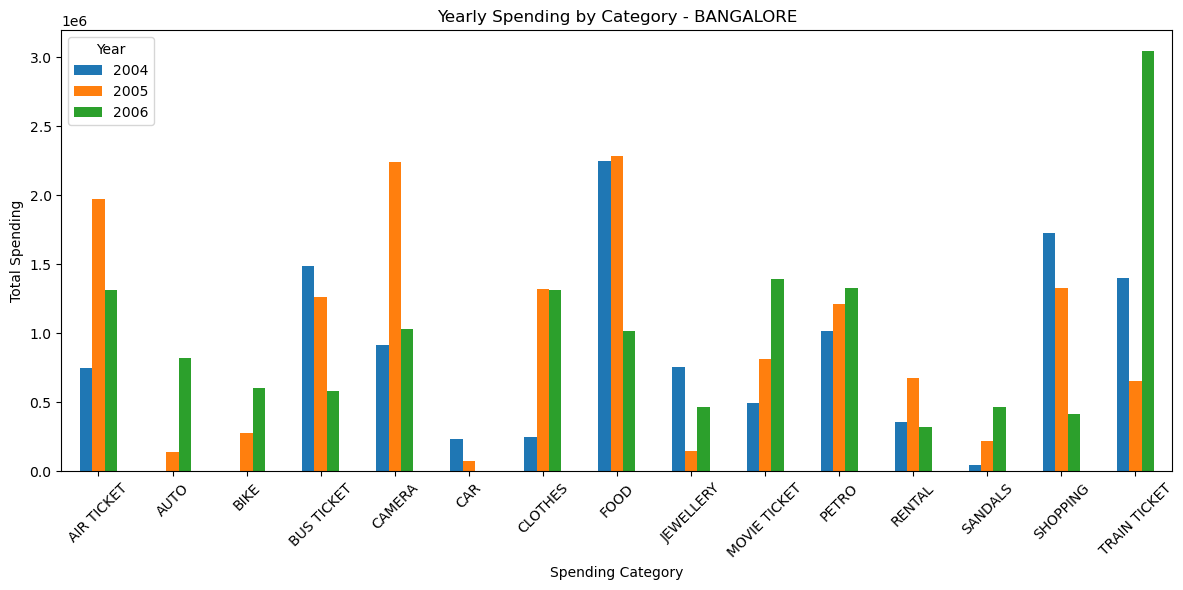

In [78]:
# Select a city

selected_city = spend['City'].mode()[0]

# Filter data for the selected city

city_data = spend[
    spend['City'] == selected_city
]

# Calculate yearly category spending

yearly_city_product = city_data.pivot_table(
    index='Type',
    columns='Year',
    values='Amount',
    aggfunc='sum',
    fill_value=0
)

# Plot

yearly_city_product.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title(
    f'Yearly Spending by Category - {selected_city}'
)

plt.xlabel('Spending Category')
plt.ylabel('Total Spending')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [79]:
# Calculate total spending by city and month

monthly_city_spend = spend.groupby(
    ['Year_Month', 'City']
)['Amount'].sum().reset_index()

display(monthly_city_spend.head())

,Year_Month,City,Amount
0,2004-01,BANGALORE,8662102.77
1,2004-01,BOMBAY,5350399.72
2,2004-01,CALCUTTA,7920520.66
3,2004-01,CHENNAI,3962503.69
4,2004-01,COCHIN,8762429.20


In [80]:
monthly_city_pivot = monthly_city_spend.pivot(
    index='Year_Month',
    columns='City',
    values='Amount'
).fillna(0)

display(monthly_city_pivot.head())

City,BANGALORE,BOMBAY,CALCUTTA,CHENNAI,COCHIN,DELHI,PATNA,TRIVANDRUM
Year_Month,,,,,,,,
2004-01,8662102.77,5350399.72,7920520.66,3962503.69,8762429.20,2564259.45,3525469.06,3532127.41
2004-02,535939.92,1016569.54,626394.70,0.00,384884.81,444497.23,50001.00,777664.64
2004-03,82428.80,507931.43,358822.88,427931.80,153175.37,291622.99,50000.00,0.00
2004-04,1405495.85,479946.78,55001.00,0.00,707487.06,310128.03,266851.54,264505.08
2004-05,783277.82,5000.50,239397.51,14664.26,806452.60,50001.50,50000.00,197783.17


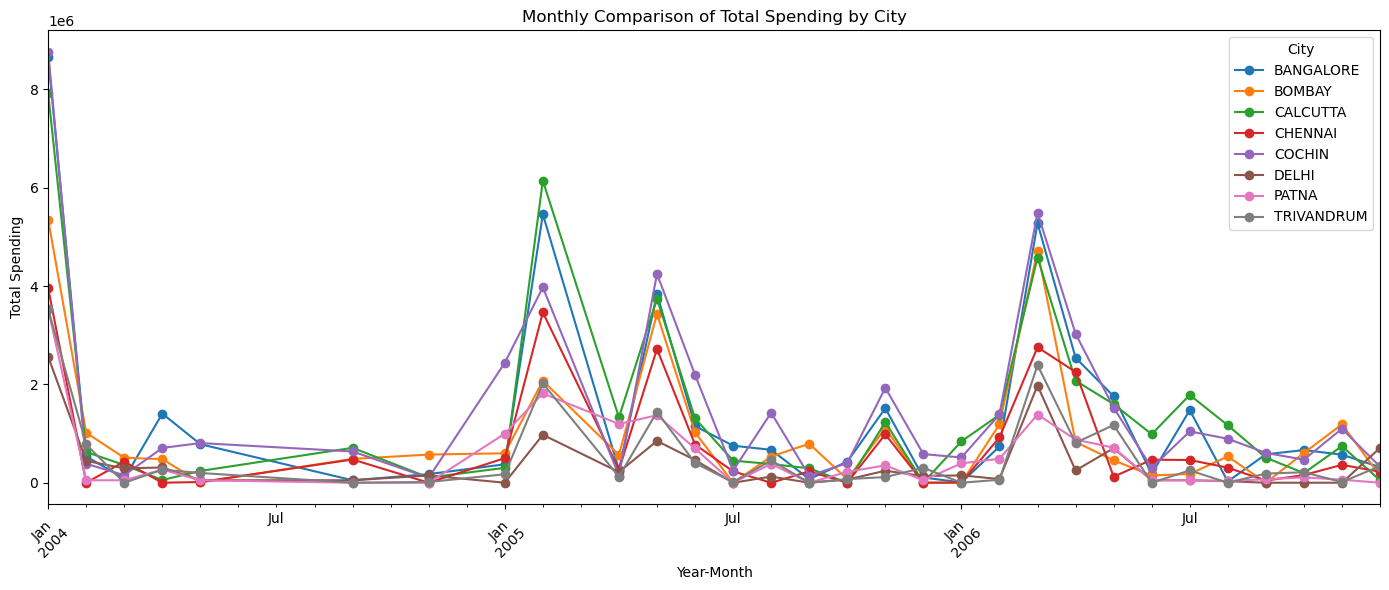

In [82]:
monthly_city_pivot.plot(
    figsize=(14, 6),
    marker='o'
)

plt.title('Monthly Comparison of Total Spending by City')
plt.xlabel('Year-Month')
plt.ylabel('Total Spending')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [83]:
print(sorted(spend['Type'].dropna().unique()))

['AIR TICKET', 'AUTO', 'BIKE', 'BUS TICKET', 'CAMERA', 'CAR', 'CLOTHES', 'FOOD', 'JEWELLERY', 'MOVIE TICKET', 'PETRO', 'RENTAL', 'SANDALS', 'SHOPPING', 'TRAIN TICKET']


In [84]:
# Identify air-ticket categories

air_ticket_mask = spend['Type'].str.contains(
    'AIR.*TICKET',
    case=False,
    na=False,
    regex=True
)

air_tickets = spend[air_ticket_mask].copy()

print("Air-ticket transaction count:", len(air_tickets))

print(air_tickets['Type'].value_counts())

Air-ticket transaction count: 147
Type
AIR TICKET    147
Name: count, dtype: int64


In [85]:
yearly_air_ticket_spend = air_tickets.groupby(
    'Year'
)['Amount'].sum()

display(yearly_air_ticket_spend)

Year
2004     4357225.35
2005    10550152.21
2006     5248469.56
Name: Amount, dtype: float64

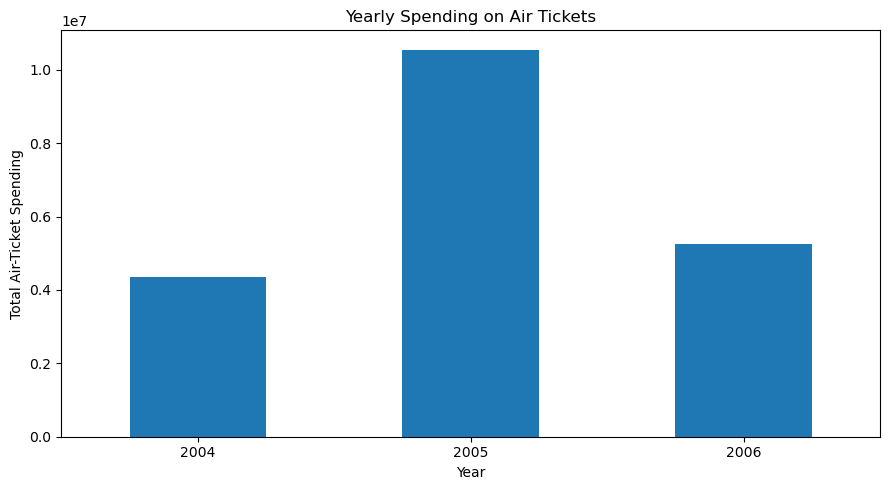

In [87]:
plt.figure(figsize=(9, 5))

yearly_air_ticket_spend.plot(
    kind='bar'
)

plt.title('Yearly Spending on Air Tickets')
plt.xlabel('Year')
plt.ylabel('Total Air-Ticket Spending')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [88]:
# Calculate monthly spending for each category

monthly_product_spend = spend.groupby(
    ['Year_Month', 'Type']
)['Amount'].sum().reset_index()

display(monthly_product_spend.head())

,Year_Month,Type,Amount
0,2004-01,AIR TICKET,3053884.61
1,2004-01,AUTO,254745.28
2,2004-01,BIKE,376633.28
3,2004-01,BUS TICKET,3563648.59
4,2004-01,CAMERA,8546992.33


In [89]:
monthly_product_pivot = monthly_product_spend.pivot(
    index='Year_Month',
    columns='Type',
    values='Amount'
).fillna(0)

display(monthly_product_pivot.head())

Type,AIR TICKET,AUTO,BIKE,BUS TICKET,CAMERA,CAR,CLOTHES,FOOD,JEWELLERY,MOVIE TICKET,PETRO,RENTAL,SANDALS,SHOPPING,TRAIN TICKET
Year_Month,,,,,,,,,,,,,,,
2004-01,3053884.61,254745.28,376633.28,3563648.59,8546992.33,1808285.79,2370537.40,5928981.00,1904642.18,1538392.99,4246095.43,2607584.26,937690.61,4937924.11,2203774.10
2004-02,658572.90,0.00,50001.00,981696.51,0.00,0.00,264892.01,300031.83,343726.40,0.00,853541.78,0.00,0.00,383489.41,0.00
2004-03,5000.50,0.00,0.00,0.00,1092224.18,0.00,50000.50,50000.00,50000.00,0.00,462931.43,0.00,47866.78,0.00,113889.88
2004-04,0.00,0.00,0.00,549087.95,483603.21,0.00,0.00,363548.29,141769.02,50000.00,90197.61,0.00,0.00,1454690.26,356519.00
2004-05,0.00,0.00,0.00,361141.31,0.00,0.00,0.00,353619.48,139648.20,0.00,0.00,986717.34,50001.50,0.00,255449.53


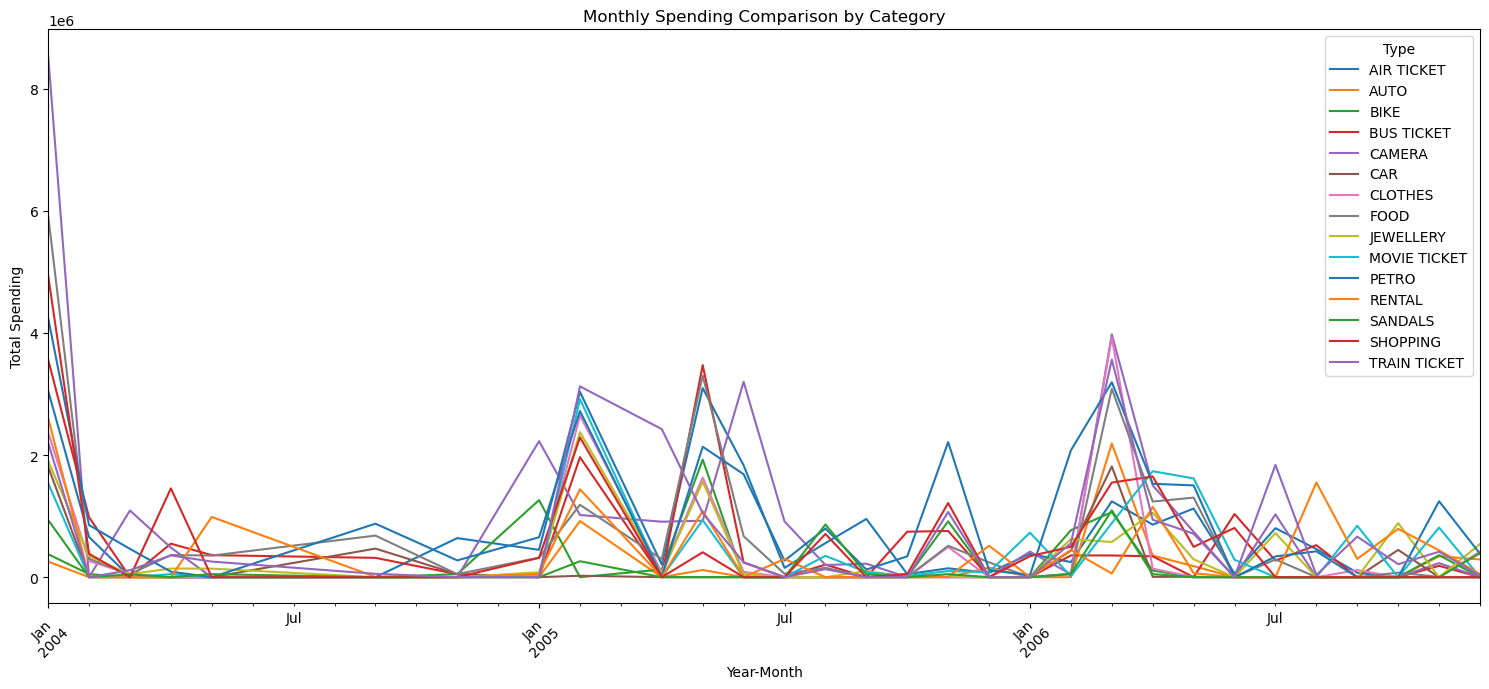

In [90]:
monthly_product_pivot.plot(
    figsize=(15, 7)
)

plt.title('Monthly Spending Comparison by Category')
plt.xlabel('Year-Month')
plt.ylabel('Total Spending')

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [91]:
# Calculate calendar-month spending across years

spend['Calendar_Month'] = spend['Month'].dt.month

calendar_month_spend = spend.groupby(
    ['Year', 'Calendar_Month', 'Type']
)['Amount'].sum().reset_index()

# Average spending for each calendar month and category

seasonal_spend = calendar_month_spend.groupby(
    ['Calendar_Month', 'Type']
)['Amount'].mean().reset_index()

seasonal_pivot = seasonal_spend.pivot(
    index='Calendar_Month',
    columns='Type',
    values='Amount'
)

display(seasonal_pivot)

Type,AIR TICKET,AUTO,BIKE,BUS TICKET,CAMERA,CAR,CLOTHES,FOOD,JEWELLERY,MOVIE TICKET,PETRO,RENTAL,SANDALS,SHOPPING,TRAIN TICKET
Calendar_Month,,,,,,,,,,,,,,,
1,1.294582e+06,254745.280,8.197534e+05,3.563649e+06,3.731320e+06,1808285.79,1.195019e+06,3.124553e+06,9.919667e+05,1133823.360,1.645184e+06,1.331293e+06,937690.610,1.865859e+06,2203774.100
2,1.314017e+06,919326.200,4.096759e+05,1.101335e+06,5.341582e+05,229302.41,9.901520e+05,5.133936e+05,1.114670e+06,1466070.120,1.884043e+06,9.427378e+05,155659.410,1.057408e+06,1840330.775
3,6.237946e+05,2189907.850,1.065988e+06,3.555713e+05,2.535030e+06,1813511.58,1.989116e+06,1.568150e+06,3.131521e+05,885885.800,1.828396e+06,5.951110e+04,571233.325,1.549438e+06,1838829.290
4,5.332221e+05,354503.560,1.172012e+05,4.451227e+05,9.651494e+05,5001.00,1.095506e+05,6.324377e+05,4.177002e+05,892770.905,5.417674e+05,1.151420e+06,50000.000,1.552114e+06,1241112.200
5,2.110500e+06,149245.360,1.925608e+06,1.917630e+06,8.347503e+05,6588.51,1.631257e+06,1.652708e+06,6.654274e+05,1276230.210,1.819759e+06,7.117242e+05,50001.500,4.523868e+05,672333.120
6,9.448079e+05,NaN,NaN,6.373434e+05,3.200530e+06,NaN,8.620208e+04,6.707124e+05,5.000000e+04,285128.750,1.686017e+06,NaN,NaN,8.059944e+05,245226.290
7,4.777513e+05,NaN,NaN,2.721124e+05,9.712422e+05,NaN,NaN,1.727584e+05,7.217967e+05,NaN,3.052318e+05,2.991001e+05,NaN,NaN,1838749.580
8,5.087785e+05,NaN,NaN,3.652798e+05,1.989224e+05,NaN,NaN,1.548919e+05,NaN,349373.100,6.108377e+05,1.550897e+06,863913.500,7.073233e+05,83394.865
9,5.133321e+05,NaN,NaN,3.164988e+05,2.208241e+05,468155.33,1.153549e+05,6.811174e+05,1.000015e+05,462038.070,5.005199e+05,1.523514e+05,50000.500,NaN,359548.075


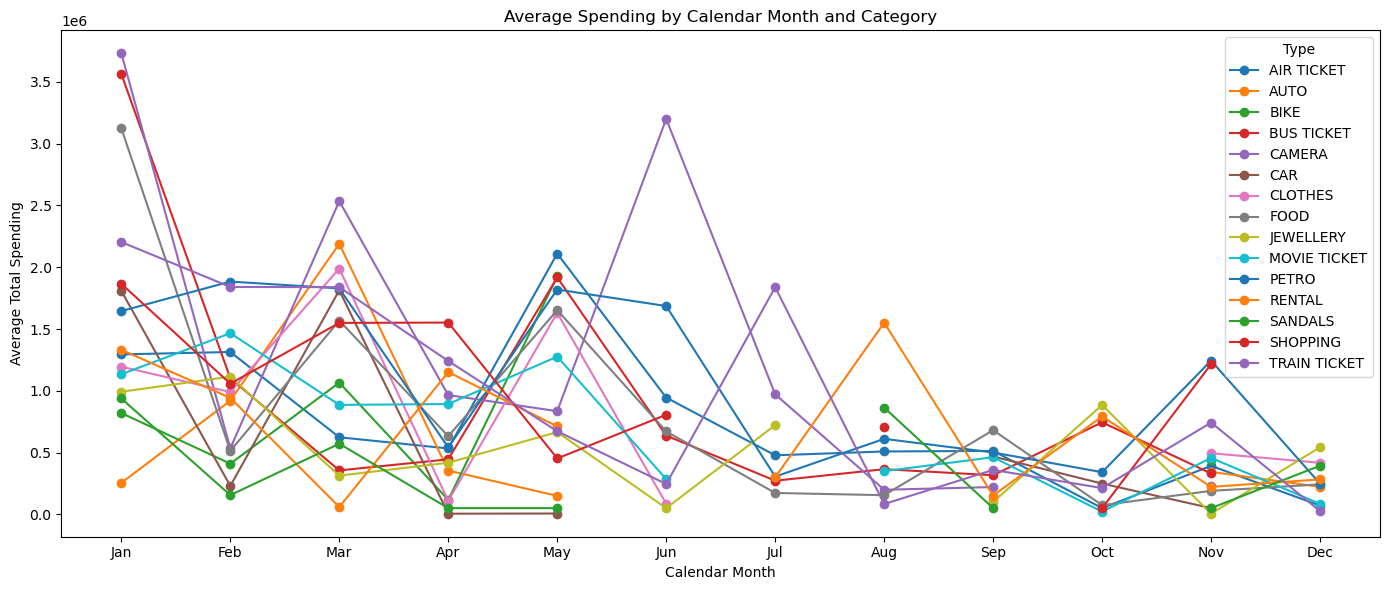

In [92]:
seasonal_pivot.plot(
    figsize=(14, 6),
    marker='o'
)

plt.title('Average Spending by Calendar Month and Category')
plt.xlabel('Calendar Month')
plt.ylabel('Average Total Spending')

plt.xticks(
    range(1, 13),
    [
        'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
        'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'
    ]
)

plt.tight_layout()
plt.show()

In [102]:
def top_10_customers_by_repayment(
    product,
    time_period,
    period_value=None
):
    """
    Find the top 10 customers in each city by repayment.

    Parameters
    ----------
    product : str
        Gold, Silver, or Platinum.

    time_period : str
        Yearly or monthly.

    period_value : int or str, optional
        For yearly analysis, provide a year such as 2005.
        For monthly analysis, provide a month such as '2005-01'.
        If omitted, all available periods are included.

    Returns
    -------
    DataFrame
        Top 10 customers by repayment in each city.
    """

    # Make a copy of the repayment data

    df = repayment.copy()

    # Validate product

    valid_products = ['Gold', 'Silver', 'Platinum']

    if product.title() not in valid_products:
        raise ValueError(
            "Product must be Gold, Silver, or Platinum."
        )

    product = product.title()

    # Filter by card product

    df = df[df['Product'] == product].copy()

    # Validate time period

    time_period = time_period.lower()

    if time_period not in ['yearly', 'monthly']:
        raise ValueError(
            "Time period must be yearly or monthly."
        )

    # Extract year and month

    df['Year'] = df['Month'].dt.year

    df['Year_Month'] = (
        df['Month'].dt.to_period('M').astype(str)
    )

    # Apply the selected period if provided

    if period_value is not None:

        if time_period == 'yearly':

            df = df[
                df['Year'] == int(period_value)
            ].copy()

        else:

            df = df[
                df['Year_Month'] == str(period_value)
            ].copy()

    # Identify the grouping column

    if time_period == 'yearly':
        period_column = 'Year'
    else:
        period_column = 'Year_Month'

    # Aggregate repayments by city and customer

    summary = df.groupby(
        ['City', period_column, 'Customer'],
        as_index=False
    )['Amount'].sum()

    # Rename repayment amount

    summary = summary.rename(
        columns={'Amount': 'Total_Repayment'}
    )

    # Rank customers within each city and period

    summary['Rank'] = summary.groupby(
        ['City', period_column]
    )['Total_Repayment'].rank(
        method='first',
        ascending=False
    )

    # Select top 10 customers

    result = summary[
        summary['Rank'] <= 10
    ].copy()

    # Sort the results

    result = result.sort_values(
        ['City', period_column, 'Rank']
    )

    return result

In [103]:
gold_yearly = top_10_customers_by_repayment(
    product='Gold',
    time_period='yearly'
)

display(gold_yearly)

,City,Year,Customer,Total_Repayment,Rank
2,BANGALORE,2004,A14,2770261.30,1.0
0,BANGALORE,2004,A1,2359797.84,2.0
1,BANGALORE,2004,A13,2337012.77,3.0
4,BANGALORE,2004,A43,1906497.47,4.0
3,BANGALORE,2004,A30,978777.17,5.0
...,...,...,...,...,...
83,PATNA,2006,A26,3330421.30,1.0
84,PATNA,2006,A66,113094.58,2.0
85,TRIVANDRUM,2004,A28,965108.49,1.0
86,TRIVANDRUM,2005,A28,2827009.82,1.0


In [104]:
silver_monthly = top_10_customers_by_repayment(
    product='Silver',
    time_period='monthly'
)

display(silver_monthly)

,City,Year_Month,Customer,Total_Repayment,Rank
1,BANGALORE,2004-01,A23,1597308.11,1.0
2,BANGALORE,2004-01,A59,1413237.57,2.0
0,BANGALORE,2004-01,A18,1311365.95,3.0
3,BANGALORE,2004-02,A72,327006.94,1.0
4,BANGALORE,2004-03,A59,175922.46,1.0
...,...,...,...,...,...
172,TRIVANDRUM,2006-03,A57,1214005.58,1.0
173,TRIVANDRUM,2006-03,A86,295851.47,2.0
174,TRIVANDRUM,2006-04,A57,77377.57,1.0
175,TRIVANDRUM,2006-05,A68,319836.49,1.0


In [113]:
platinum_2005 = top_10_customers_by_repayment(
    product='Platinum',
    time_period='yearly',
    period_value=2005
)

display(platinum_2005)

,City,Year,Customer,Total_Repayment,Rank


In [106]:
gold_january = top_10_customers_by_repayment(
    product='Gold',
    time_period='monthly',
    period_value='2005-01'
)

display(gold_january)

,City,Year_Month,Customer,Total_Repayment,Rank
1,BANGALORE,2005-01,A13,386518.41,1.0
2,BANGALORE,2005-01,A30,228554.19,2.0
0,BANGALORE,2005-01,A1,165972.88,3.0
3,BANGALORE,2005-01,A43,71540.68,4.0
4,BOMBAY,2005-01,A12,13379.96,1.0
7,CALCUTTA,2005-01,A60,443375.38,1.0
5,CALCUTTA,2005-01,A10,211299.62,2.0
6,CALCUTTA,2005-01,A29,201994.21,3.0
8,CHENNAI,2005-01,A27,42552.74,1.0
10,COCHIN,2005-01,A61,379523.96,1.0


In [94]:
# Total spending by card product

product_spending = spend.groupby(
    'Product'
)['Amount'].sum()

# Total repayment by card product

product_repayment = repayment.groupby(
    'Product'
)['Amount'].sum()

# Combine the results

product_comparison = pd.concat(
    [
        product_spending.rename('Total_Spend'),
        product_repayment.rename('Total_Repayment')
    ],
    axis=1
).fillna(0)

display(product_comparison)

,Total_Spend,Total_Repayment
Product,,
Gold,1.462004e+08,1.580360e+08
Platimum,5.638741e+07,1.343367e+08
Silver,1.719332e+07,7.946231e+07


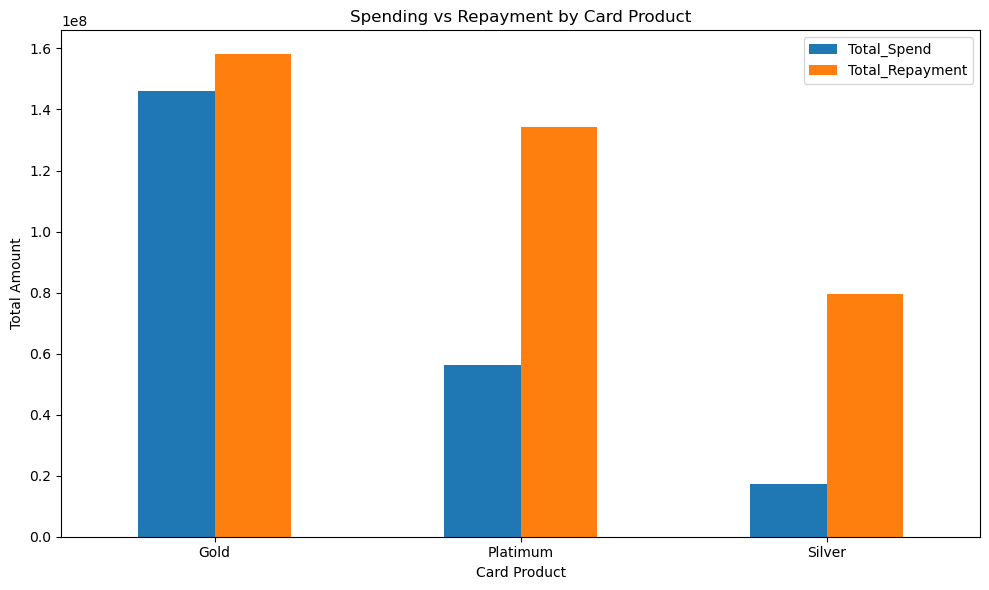

In [95]:
product_comparison.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Spending vs Repayment by Card Product')
plt.xlabel('Card Product')
plt.ylabel('Total Amount')

plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [96]:
segment_spend = spend.groupby(
    'Segment'
)['Amount'].sum().sort_values(
    ascending=False
)

display(segment_spend)

Segment
Normal Salary    58282187.02
Self Employed    47841346.19
Salaried_Pvt     45046040.79
Govt             34867160.16
Salaried_MNC     33744351.07
Name: Amount, dtype: float64

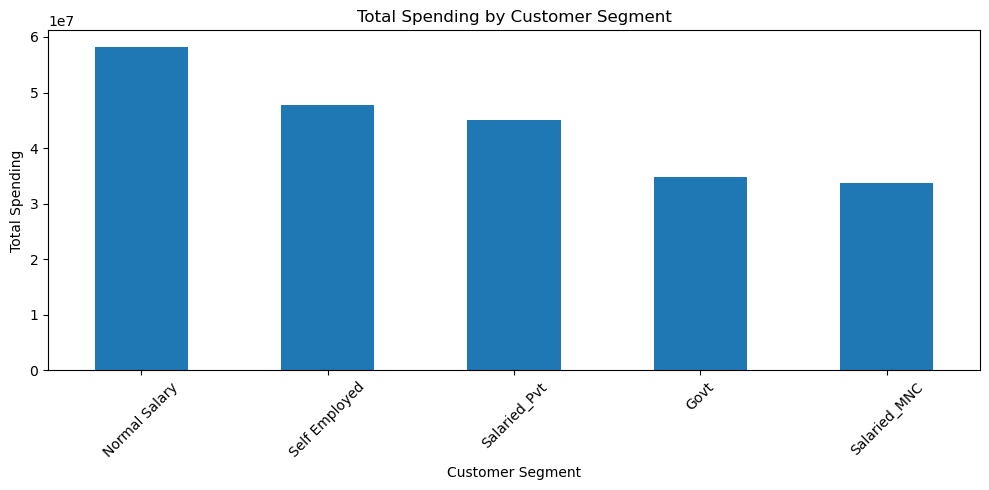

In [97]:
plt.figure(figsize=(10, 5))

segment_spend.plot(kind='bar')

plt.title('Total Spending by Customer Segment')
plt.xlabel('Customer Segment')
plt.ylabel('Total Spending')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [98]:
print(
    "Customers below age 18:",
    (customer['Age'] < 18).sum()
)

Customers below age 18: 0


In [99]:
print(
    "Spending transactions above limit:",
    (spend['Amount'] > spend['Limit']).sum()
)

Spending transactions above limit: 0


In [100]:
print(
    "Repayment transactions above limit:",
    (repayment['Amount'] > repayment['Limit']).sum()
)

Repayment transactions above limit: 600


In [114]:
# Save the main analysis outputs to Excel

with pd.ExcelWriter(
    'Credit_Card_Analysis_Results.xlsx',
    engine='openpyxl'
) as writer:

    monthly_summary.to_excel(
        writer,
        sheet_name='Monthly Profit',
        index=False
    )

    city_product_year.to_excel(
        writer,
        sheet_name='City Product Year',
        index=False
    )

    monthly_city_spend.to_excel(
        writer,
        sheet_name='Monthly City Spend',
        index=False
    )

    monthly_product_spend.to_excel(
        writer,
        sheet_name='Monthly Product Spend',
        index=False
    )

    top_10_customers.reset_index().to_excel(
        writer,
        sheet_name='Top 10 Repayment',
        index=False
    )

    product_comparison.to_excel(
        writer,
        sheet_name='Product Comparison'
    )

print("Analysis results saved successfully.")

Analysis results saved successfully.
